## 4-5

In [12]:
import torch
import torch.nn as nn
import torch.utils.data as Data
import matplotlib.pyplot as plt


x = torch.unsqueeze(torch.linspace(-1, 1, 500), dim=1)
y = x.pow(3)

LR = 0.01
batch_size = 15
epoches = 5
torch.manual_seed(42)

dataset = Data.TensorDataset(x, y)
loader = Data.DataLoader(
    dataset=dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
)


class Net(nn.Module):
    def __init__(self, n_input, n_hidden, n_output):
        super().__init__()
        self.hidden_layer = torch.nn.Linear(n_input, n_hidden)
        self.output_layer = torch.nn.Linear(n_hidden, n_output)

    def forward(self, x):
        x = self.hidden_layer(x)
        x = torch.relu(x)
        x = self.output_layer(x)
        return x

def train():
    net_SGD = Net(1, 10, 1)
    net_Momentum = Net(1, 10, 1)
    net_AdaGrad = Net(1, 10, 1)
    net_RMSProp = Net(1, 10, 1)
    net_Adam = Net(1, 10, 1)
    nets = [net_SGD, net_Momentum, net_AdaGrad, net_RMSProp, net_Adam]

    optimizer_SGD = torch.optim.SGD(
        net_SGD.parameters(), 
        lr=LR,
    )
    optimizer_Momentum = torch.optim.SGD(
        net_Momentum.parameters(), 
        lr=LR,
        momentum=0.6,
    )
    optimizer_AdaGrad = torch.optim.Adagrad(
        net_AdaGrad.parameters(),
        lr=LR,
        lr_decay=0,
    )
    optimizer_RMSProp = torch.optim.RMSprop(
        net_RMSProp.parameters(),
        lr=LR,
        alpha=0.9,
    )
    optimizer_Adam = torch.optim.Adam(
        net_Adam.parameters(),
        lr=LR,
        betas=(0.9, 0.99),
        )
    optimizers = [optimizer_SGD, optimizer_Momentum, optimizer_AdaGrad,
                  optimizer_RMSProp, optimizer_Adam]

    loss_function = torch.nn.MSELoss()
    losses = [], [], [], [], []

    for epoch in range(epoches):
        for step, (batch_x, batch_y) in enumerate(loader):
            for net, optimizer, loss_list in zip(nets, optimizers, losses):
                optimizer.zero_grad()
                pred_y = net(batch_x)
                loss = loss_function(pred_y, batch_y)
                loss.backward()
                optimizer.step()
                loss_list.append(loss.data.numpy())

    plt.figure(figsize=(12, 7))
    labels = ['SGD', 'Momentum', 'AdaGrad', 'RMSProp', 'Adam']
    for i, loss in enumerate(losses):
        plt.plot(loss, label=labels[i])
    plt.legend(loc='upper right', fontsize=15)
    plt.tick_params(labelsize=13)
    plt.xlabel('Training Steps', size=15)
    plt.ylabel('Loss', size=15)
    plt.ylim((0, 0.3))
    plt.show()

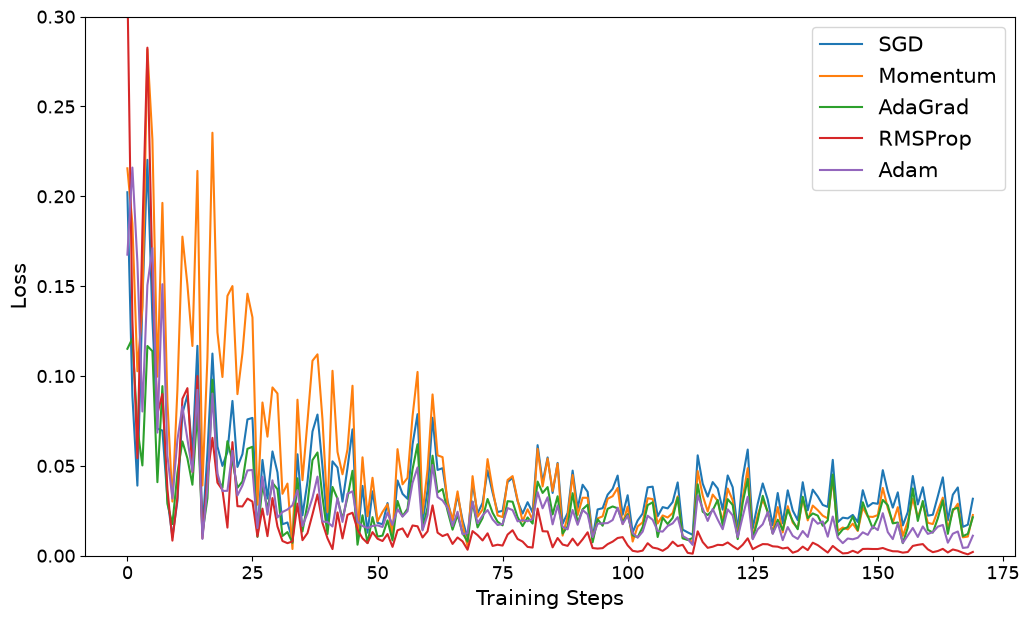

In [13]:
train()

## 4-6-1

In [18]:
import torch

print(torch.arange(12).reshape((3, 4)))

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])


## 4-6-2

In [19]:
import torch

zeros = torch.zeros(3, 3)
ones = torch.ones(3, 3)
print(zeros, "\n", ones)

tensor([[0., 0., 0.],
        [0., 0., 0.],
        [0., 0., 0.]]) 
 tensor([[1., 1., 1.],
        [1., 1., 1.],
        [1., 1., 1.]])


## 4-6-3

In [20]:
import torch

tensor = torch.randn(2, 2)
print(tensor)

tensor([[-0.7208, -0.7698],
        [ 0.0366,  0.3688]])


## 4-6-4

In [21]:
import numpy as np
import torch

arr = np.arange(1, 10)
tsr = torch.from_numpy(arr)
print(tsr)

tensor([1, 2, 3, 4, 5, 6, 7, 8, 9])


## 4-6-5

In [22]:
import torch

tsr = torch.zeros(3, 4)
print(tsr)

tensor([[0., 0., 0., 0.],
        [0., 0., 0., 0.],
        [0., 0., 0., 0.]])


## 4-6-6

In [24]:
import torch

tsr = torch.randn(3, 3)

after_relu = torch.relu(tsr)
after_sigmoid = torch.sigmoid(tsr)
after_tanh = torch.tanh(tsr)
after_leakyrelu = torch.nn.LeakyReLU()(tsr)

print(f"Original: {tsr}")
print(f"ReLU: {after_relu}")
print(f"Sigmoid: {after_sigmoid}")
print(f"Tanh: {after_tanh}")
print(f"LeakyReLU: {after_leakyrelu}")

Original: tensor([[ 0.8391, -1.2442, -0.4766],
        [-0.8058,  0.4634,  0.7677],
        [-1.1028,  1.7588, -1.8872]])
ReLU: tensor([[0.8391, 0.0000, 0.0000],
        [0.0000, 0.4634, 0.7677],
        [0.0000, 1.7588, 0.0000]])
Sigmoid: tensor([[0.6983, 0.2237, 0.3831],
        [0.3088, 0.6138, 0.6830],
        [0.2492, 0.8531, 0.1316]])
Tanh: tensor([[ 0.6853, -0.8467, -0.4435],
        [-0.6673,  0.4329,  0.6456],
        [-0.8015,  0.9424, -0.9551]])
LeakyReLU: tensor([[ 0.8391, -0.0124, -0.0048],
        [-0.0081,  0.4634,  0.7677],
        [-0.0110,  1.7588, -0.0189]])


## 4-6-7

In [29]:
import torch
import torch.nn as nn

predictions = torch.randn(10, 10)
targets = torch.randint(0, 10, (10,))

mse_loss = nn.MSELoss()
print(f"MSE Loss: {mse_loss(predictions, targets)}")

cross_entropy_loss = nn.CrossEntropyLoss()
print(f"CrossEntropy Loss: {cross_entropy_loss(predictions, targets)}")

cosine_similarity_loss = nn.CrossEntropyLoss()
print(f"Cosine Similarity Loss: cosine_similarity_loss(predictions, targets)")

MSE Loss: 20.6793155670166
CrossEntropy Loss: 2.2031049728393555
Cosine Similarity Loss: cosine_similarity_loss(predictions, targets)
